# Example I · Gradient descent: Figure 1에서 Theorem 3까지

Example I은 [공통 분석 흐름](00_Common_analysis_pipeline.ipynb)에서 소개한 다섯 단계에 따라 GD를 분석하는 첫 사례다. 알고리즘과 가정에서 출발하여 potential의 계수를 수치적으로 탐색하고, 계수의 형태를 단순화한 뒤, 선택한 계수식으로 potential 부등식을 해석적으로 증명한다. 이 사례의 주목표는 gradient norm **제곱**의 수렴률을 구하는 것이다.

실험은 $L=1$, $\mu=0$, $\delta_k=1/L$에서 진행한다. 각 단계에서 얻은 결과를 다음 단계의 분석에 사용한다. 뒤의 SGD와 averaging에서도 같은 분석 틀을 사용하면서 무엇을 추가로 고려해야 하는지 살펴본다.

| 공통 단계 | 이번 사례의 질문 | 얻을 결과 |
| --- | --- | --- |
| 1단계 · 알고리즘과 가정 | 어떤 업데이트식을 사용하며 함수에 어떤 가정을 두는가? | $L$-smooth convex 함수와 고정 step-size GD |
| 2단계 · Parameterized potential 설정 | 어떤 potential로 최종 gradient norm 제곱의 상한을 구할 것인가? | 네 계수 $a_k,b_k,c_k,d_k$와 $b_N$ 최대화 목적 |
| 3단계 · LMI/SDP로 계수 수치 탐색 | 어떤 계수를 택하면 주어진 가정 아래에서 potential이 매 단계 증가하지 않는가? | Gram 표현, interpolation, 함수값 항의 소거 조건과 LMI, 수치 계수 수열 |
| 4단계 · 계수 패턴 관찰과 단순화 | 큰 $b_N$을 유지하면서 어떤 항을 단순화할 수 있는가? | Figure 1의 비교와 $a_k=L^2$, $c_k=0$인 potential 선택 |
| 5단계 · 해석적 potential inequality와 수렴률 | 선택한 계수식이 왜 모든 단계에서 potential 부등식을 만족하는가? | Theorem 3의 점화식과 증명, gradient norm 제곱의 $O(k^{-2})$ 상한 |

[논문](https://proceedings.mlr.press/v99/taylor19a.html) ·
[로컬 PDF](../docs/Stochastic%20first-order%20methods%20non-asymptotic%20and%20computer-aided%20analyses%20via%20potential%20functions.pdf) ·
[참조 코드](../1_Deterministic_SmoothConvex/A_GradientDescent.py)

해당 범위는 §3.2.1 pp.6–7, Appendix D.1 p.25, Appendix D.4 pp.34–36이다.


## 1단계 · 알고리즘과 가정

$f\in\mathcal F_L$는 $L$-smooth convex 함수이고, $x_\star\in\arg\min f$, $f_\star=f(x_\star)$, $g_k=\nabla f(x_k)$로 둔다. Gradient descent의 한 단계는

$$x_{k+1}=x_k-L^{-1}g_k$$

이다. 정확한 gradient를 사용하는 이 업데이트식과 함수 클래스의 성질이 이후 분석의 출발점이다.

## 2단계 · Parameterized potential 설정

알고리즘과 함수 클래스가 정해졌으므로, 이제 매 단계 증가하지 않는 potential을 찾아 최종 gradient norm 제곱의 상한을 구한다. 다음 형태를 선택하고 계수 수열을 결정변수로 둔다.

$$\phi_k^f=a_k\|x_k-x_\star\|^2+b_k\|g_k\|^2
+2c_k\langle g_k,x_k-x_\star\rangle+d_k(f(x_k)-f_\star).$$

코드에서는 이차항의 계수를 대칭행렬

$$Q_k=\begin{pmatrix}a_k&c_k\\c_k&b_k\end{pmatrix}$$

로 묶는다. 중간 계수의 부호에는 제약을 두지 않으며, $Q_k\succeq0$도 요구하지 않는다.

초기에는 거리항만, 마지막에는 gradient norm 제곱 항만 남도록 경계조건을 정하면

$$\phi_{k+1}^f\le\phi_k^f,\quad
\phi_0^f=L^2\|x_0-x_\star\|^2,\quad\phi_N^f=b_N\|g_N\|^2
\quad\Longrightarrow\quad
\|g_N\|^2\le\frac{L^2\|x_0-x_\star\|^2}{b_N}.$$

여기서 potential 감소는 그 값이 이전 단계보다 커지지 않는다는 뜻이다. 따라서 $b_N$이 클수록 더 작은 상한을 얻는다. 이번 SDP는 step-size를 $1/L$로 고정하고, 이 감소 조건을 만족하는 potential 계수 중에서 $b_N$을 최대화한다.


In [1]:
from pathlib import Path
from time import perf_counter
import importlib.util

import cvxpy as cp
import matplotlib.pyplot as plt
import mosek
import numpy as np
from IPython.display import Markdown, display

repo_root = next(
    (candidate for candidate in (Path.cwd(), *Path.cwd().parents)
     if (candidate / "1_Deterministic_SmoothConvex/A_GradientDescent.py").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Run this notebook from the repository root or its ipynb directory.")
license_path = repo_root / "mosek.lic"
if license_path.is_file():
    mosek.Env().putlicensepath(str(license_path))

adapter_path = repo_root / "1_Deterministic_SmoothConvex/saveData.py"
spec = importlib.util.spec_from_file_location("gd_saveData", adapter_path)
solver_adapter = importlib.util.module_from_spec(spec)
spec.loader.exec_module(solver_adapter)
solve = solver_adapter.solve

### 실험 설정

$$L=1,\quad\mu=0,\quad N=100,\quad\delta_k=L^{-1},\quad\texttt{relax}=0.$$

먼저 중간 계수를 자유롭게 두는 `relax=0`으로 시작한다. 최적화에는 MOSEK을 사용하고, 제약 만족 여부를 판단하는 허용오차를 $10^{-8}$로 설정한다. `solve`는 참조 코드의 `saveData.py`에서 가져온 solver 호출 함수다. 코드의 `m`은 수식의 $\mu$에 대응한다.


In [2]:
L = 1.0
m = 0.0
N_FIGURE = 100
N = N_FIGURE
relax = 0
solver = "MOSEK"
tolerance = 1e-8
verbose = False
delta = lambda k: 1 / L

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.22,
    "font.size": 11,
})
print(f"CVXPY {cp.__version__} | MOSEK {'.'.join(map(str, mosek.Env.getversion()))}")
print(f"L={L:g}, mu={m:g}, step=1/L, N={N}, solver={solver}")

CVXPY 1.9.3 | MOSEK 11.2.6
L=1, mu=0, step=1/L, N=100, solver=MOSEK


### 기본 실험의 경계조건

앞에서 선택한 초기·최종 potential에 해당하는 $Q_k,d_k$의 값을 다음과 같이 정한다.

$$Q_0=\begin{pmatrix}L^2&0\\0&0\end{pmatrix},\qquad
Q_N=\begin{pmatrix}0&0\\0&\tau\end{pmatrix},\qquad
d_0=d_N=0,\qquad b_N=\tau.$$

여기서 $\tau$는 최대화할 최종 계수다. 초기 potential에는 거리항만, 최종 potential에는 gradient norm 제곱 항만 남는다.

참조 코드의 딕셔너리 키는 1부터 시작한다. 따라서 수식의 $Q_k,d_k$는 각각 `Q[k+1]`, `d[k+1]`에 대응하고, 업데이트 $k\to k+1$의 multiplier는 `lam[k+1]`에 저장한다.


In [3]:
t_start = perf_counter()
a0, b0, c0, d0 = L**2, 0, 0, 0
tau = cp.Variable(name="tau")
aN, bN, cN, dN = 0, tau, 0, 0

Q0 = cp.bmat([[a0, c0], [c0, b0]])
QN = cp.bmat([[aN, cN], [cN, bN]])
Q = {1: Q0, N + 1: QN}
d = {1: d0, N + 1: dN}

## 3단계 · LMI/SDP로 계수 수치 탐색

앞 단계에서 potential의 형태와 경계조건을 정했다. 이제 같은 함수 클래스에 속하는 모든 문제에서 potential이 매 단계 증가하지 않도록 중간 계수와 multiplier를 찾는다. 이를 위해 potential 차이를 Gram 행렬과 함수값에 대한 선형식으로 쓰고, interpolation 부등식을 결합해 함수값 항의 소거 조건과 LMI를 구성한다.

### 한 단계의 Gram 표현

최적점에서는 $g_\star=0$이고, 좌표와 함수값의 기준을 옮겨 $x_\star=0$, $f_\star=0$으로 둔다. 한 단계에서 필요한 벡터와 함수값을 다음과 같이 모은다.

$$P=[x_k\quad g_k\quad g_{k+1}],\qquad G=P^\top P\succeq0,\qquad
\mathbf F=\begin{pmatrix}f(x_k)\\f(x_{k+1})\end{pmatrix}.$$

$G$의 각 성분은 $P$의 두 열 사이의 내적이다. 모든 $v\in\mathbb R^3$에 대해 $v^\top Gv=\|Pv\|^2\ge0$이므로 $G\succeq0$이다. 반대로 PSD 행렬은 $P^\top P$로 분해할 수 있으므로, 차원에 제한을 두지 않는 분석에서는 이 조건으로 실제 벡터들의 내적 관계를 표현할 수 있다.

아래 표의 굵은 기호는 실제 점과 gradient를 $P$에 있는 열벡터의 선형결합으로 나타내거나 함수값을 선택하는 **계수벡터**다. $e_1,e_2,e_3$를 $\mathbb R^3$의 표준기저로 두면

$$\begin{array}{c|ccc}
p&\star&k&k+1\\\hline
\mathbf x_p&0&e_1&e_1-L^{-1}e_2\\
\mathbf g_p&0&e_2&e_3\\
\mathbf f_p&0&(1,0)^\top&(0,1)^\top
\end{array}$$

이다. 특히 $P\mathbf x_{k+1}=x_k-L^{-1}g_k$이므로 다음 점의 계수벡터에 이미 GD 업데이트가 반영되어 있다. 수식의 계수벡터는 열벡터이며, 코드에서는 이를 행벡터로 저장한다.


In [4]:
dimG = 3
dimF = 2
nbPts = 3
xk = np.zeros((1, dimG))
xk[0, 0] = 1
xs = np.zeros((1, dimG))
gxk = np.zeros((1, dimG))
gxk[0, 1] = 1
gxk1 = np.zeros((1, dimG))
gxk1[0, 2] = 1
gxs = np.zeros((1, dimG))
fxk = np.zeros((1, dimF))
fxk[0, 0] = 1
fxk1 = np.zeros((1, dimF))
fxk1[0, 1] = 1
fxs = np.zeros((1, dimF))
xk1 = lambda k: xk - delta(k) * gxk

print("x_k =", xk, "  g_k =", gxk, "  g_{k+1} =", gxk1)
print("x_{k+1} =", xk1(1), "  f_k =", fxk, "  f_{k+1} =", fxk1)

x_k = [[1. 0. 0.]]   g_k = [[0. 1. 0.]]   g_{k+1} = [[0. 0. 1.]]
x_{k+1} = [[ 1. -1.  0.]]   f_k = [[1. 0.]]   f_{k+1} = [[0. 1.]]


### Potential을 Gram 행렬과 함수값의 선형식으로 쓰기

거리항·gradient norm 제곱 항·교차항의 계수행렬 $Q_k$와 두 상태의 계수벡터를 다음과 같이 묶는다.

$$Q_k=\begin{pmatrix}a_k&c_k\\c_k&b_k\end{pmatrix},\quad
E_k=[\mathbf x_k\ \mathbf g_k],\quad
E_{k+1}=[\mathbf x_{k+1}\ \mathbf g_{k+1}],\quad V_k=E_kQ_kE_k^\top.$$

그러면 potential의 이차항은 $\operatorname{Tr}(GV_k)$가 되고, 한 단계 차이는

$$\Delta\phi_k=\operatorname{Tr}(G(V_{k+1}-V_k))+
(d_{k+1}\mathbf f_{k+1}-d_k\mathbf f_k)^\top\mathbf F$$

로 표현된다. 원래 벡터에 대한 이차식이 $G$와 $\mathbf F$에 대한 선형식으로 바뀐 것이다.

$E_k$와 $E_{k+1}$는 각각 코드의 `statesKG`, `statesK1G(k)`에 대응하는 $3\times2$ 행렬이다.


In [5]:
statesKG = np.hstack(((xk - xs).T, gxk.T))
statesK1G = lambda k: np.hstack(((xk1(k) - xs).T, gxk1.T))
statesKF = fxk
statesK1F = fxk1
print("E_k =\n", statesKG)
print("E_{k+1} =\n", statesK1G(1))

E_k =
 [[1. 0.]
 [0. 1.]
 [0. 0.]]
E_{k+1} =
 [[ 1.  0.]
 [-1.  0.]
 [ 0.  1.]]


### Smooth convex interpolation 부등식

세 점 $\star,k,k+1$에서 서로 다른 점을 고르는 순서쌍 $(p,q)$는 여섯 개다. 각 순서쌍에는 함수 클래스의 성질을 나타내는 다음 부등식이 성립한다.

$$\mathcal I_{p,q}=f(x_p)-f(x_q)-\langle g_q,x_p-x_q\rangle
-\frac1{2L}\|g_p-g_q\|^2\ge0.$$

이 식도 함수값 항과 Gram 행렬의 선형식으로 나눌 수 있다.

$$T_{p,q}=[\mathbf x_p\ \mathbf x_q\ \mathbf g_p\ \mathbf g_q],\quad
M_{p,q}=T_{p,q}MT_{p,q}^{\top},\quad
\mathcal I_{p,q}=(\mathbf f_p-\mathbf f_q)^\top\mathbf F+\operatorname{Tr}(GM_{p,q}).$$

참조 코드는 $\mu$-strongly convex 함수까지 포함하는 공통 interpolation 행렬

$$M=\frac1{2(L-\mu)}\begin{pmatrix}
-L\mu&L\mu&\mu&-L\\L\mu&-L\mu&-\mu&L\\
\mu&-\mu&-1&1\\-L&L&1&-1
\end{pmatrix}$$

을 사용한다. 이번 실험에서는 $\mu=0$이므로 위의 smooth convex 부등식이 된다. $M$은 모든 순서쌍에서 공통으로 쓰고, $M_{p,q}$는 각 점의 계수벡터를 대입해 만든다. 코드의 `TT`는 $T_{p,q}^\top$에 대응한다.


In [6]:
M = 1 / (2 * (L - m)) * np.array([
    [-L * m,  L * m,  m, -L],
    [ L * m, -L * m, -m,  L],
    [     m,     -m, -1,  1],
    [    -L,      L,  1, -1],
])
print("M =\n", M)

M =
 [[-0.   0.   0.  -0.5]
 [ 0.  -0.  -0.   0.5]
 [ 0.  -0.  -0.5  0.5]
 [-0.5  0.5  0.5 -0.5]]


### 자유로운 중간 계수와 interpolation multiplier

초기·최종 potential 사이의 상태 $k=1,\ldots,N-1$에서는

$$Q_k=\begin{pmatrix}a_k&c_k\\c_k&b_k\end{pmatrix}\in\mathbb S^2,
\qquad d_k\in\mathbb R$$

를 모두 결정변수로 둔다. $Q_k$에는 대칭성만 요구하며, 별도의 PSD 조건이나 계수의 부호 조건은 두지 않는다.

각 업데이트의 여섯 interpolation 부등식에는 독립적인 비음수 multiplier를 둔다. 이 가중치들도 potential 계수와 함께 SDP가 결정한다. 코드의 `lam[k]`는 $3\times3$ 배열이며, 같은 점끼리의 interpolation에 해당하는 대각 원소는 합에서 제외한다.


In [7]:
lam = {}
for k in range(1, N + 1):
    if k < N:
        d[k + 1] = cp.Variable(name=f"d_{k+1}")
        Q[k + 1] = cp.Variable((2, 2), symmetric=True, name=f"Q_{k+1}")
    lam[k] = cp.Variable((nbPts, nbPts), name=f"lambda_{k}")

### 먼저 potential의 차이를 구성하기

이차항의 계수행렬 차이와 함수값 항의 계수벡터 차이를 각각

$$\Delta V_k=E_{k+1}Q_{k+1}E_{k+1}^{\top}-E_kQ_kE_k^{\top},\qquad
\Delta d_k=d_{k+1}\mathbf f_{k+1}-d_k\mathbf f_k$$

로 둔다. $L=1$에서 첫 번째 행렬을 전개하면

$$\Delta V_k=\begin{pmatrix}
a_{k+1}-a_k&-a_{k+1}-c_k&c_{k+1}\\
-a_{k+1}-c_k&a_{k+1}-b_k&-c_{k+1}\\
c_{k+1}&-c_{k+1}&b_{k+1}
\end{pmatrix}$$

이다. 다음 코드에서는 이 두 차이를 먼저 만들고, 이어서 interpolation 부등식의 가중합을 더한다.


In [8]:
cons_SDP = {}
cons_LIN = {}
for k in range(1, N + 1):
    cons_SDP[k] = (
        -statesKG @ Q[k] @ statesKG.T
        + statesK1G(k) @ Q[k + 1] @ statesK1G(k).T
    )
    cons_LIN[k] = -d[k] * statesKF + d[k + 1] * statesK1F

### Interpolation 부등식의 가중합을 더하기

각 interpolation 부등식의 좌변과 가중치가 비음수이므로

$$\Delta\phi_k\le\Delta\phi_k+\sum_{p\ne q}\lambda_{p,q}\mathcal I_{p,q},\qquad\lambda_{p,q}\ge0$$

이다. 따라서 오른쪽의 가중합이 0 이하가 되도록 만들면 potential 감소를 보장할 수 있다. 행렬과 함수값의 계수를 각각 모으면

$$R_k=\Delta V_k+\sum_{p\ne q}\lambda_{p,q}M_{p,q},\qquad
r_k=\Delta d_k+\sum_{p\ne q}\lambda_{p,q}(\mathbf f_p-\mathbf f_q)$$

이고, 가중합은 $\operatorname{Tr}(GR_k)+r_k^\top\mathbf F$가 된다.

코드의 점 번호 `1, 2, 3`은 각각 $\star,k,k+1$에 대응한다. 코드의 `G`, `F`는 gradient·함수값 **계수벡터를 담은 딕셔너리**이므로, 수식의 Gram 행렬 $G$ 및 함수값 벡터 $\mathbf F$와 구별한다.


In [9]:
for k in range(1, N + 1):
    X = {1: xs, 2: xk, 3: xk1(k)}
    G = {1: gxs, 2: gxk, 3: gxk1}
    F = {1: fxs, 2: fxk, 3: fxk1}
    for i in range(1, nbPts + 1):
        for j in range(1, nbPts + 1):
            if i != j:
                xi, xj = X[i], X[j]
                gi, gj = G[i], G[j]
                fi, fj = F[i], F[j]
                TT = np.vstack((xi, xj, gi, gj))
                cons_SDP[k] = cons_SDP[k] + lam[k][i - 1, j - 1] * (TT.T @ M @ TT)
                cons_LIN[k] = cons_LIN[k] + lam[k][i - 1, j - 1] * (fi - fj)

### 함수값 항의 소거 조건과 LMI로 SDP 구성하기

Interpolation 조건을 가중합에 포함한 뒤에는 모든 $G\succeq0$와 자유로운 함수값 벡터 $\mathbf F$에 대해 그 가중합이 0 이하가 되도록 한다.

함수값 계수 $r_k$가 0이 아니면 $\mathbf F$를 바꾸어 가중합을 얼마든지 크게 만들 수 있으므로 $r_k=0$이어야 한다. 그러면 행렬항만 남는다. 모든 $G\succeq0$에 대해 $\operatorname{Tr}(GR_k)\le0$이 되도록 하는 조건이 $R_k\preceq0$이며, 이것이 한 단계의 **LMI**다.

모든 업데이트의 조건을 모아 최종 계수 $\tau=b_N$을 최대화한다.

$$\boxed{\max\tau\quad\text{s.t.}\quad\tau\ge0,\quad
R_k\preceq0,\quad r_k=0,\quad\lambda^{(k)}\ge0,\quad k=0,\ldots,N-1.}$$

이것이 Appendix D.4의 한 단계 potential 감소 조건을 사용한 SDP다. 코드의 `lam[k] >= 0`은 원소별 비음수 조건이다. 전체 문제에는 $N$개의 $3\times3$ LMI와 함수값 계수에 대한 $2N$개의 스칼라 등식이 들어간다. Gram 행렬 $G$를 직접 최적화하지 않고 potential 계수와 multiplier를 구한다.


In [10]:
cons = [tau >= 0]
for k in range(1, N + 1):
    cons.append(cons_SDP[k] << 0)
    cons.append(cons_LIN[k] == 0)
    cons.append(lam[k] >= 0)
obj = tau
problem = cp.Problem(cp.Minimize(-obj), cons)
print(f"N={N}: {N} LMIs, {2 * N} scalar equalities, {N} nonnegative 3 x 3 multipliers")

N=100: 100 LMIs, 200 scalar equalities, 100 nonnegative 3 x 3 multipliers


### SDP를 풀어 최종 계수 구하기

코드는 $-\tau$를 최소화하여 $b_N$을 최대화한다.

$$\min(-\tau)=-\max b_N.$$

다음 출력에서 solver 상태와 $N=100$의 최종 계수 $b_N$을 확인한다.


In [11]:
solver_opt = {
    "solver": solver,
    "verbose": verbose,
    "mosek_params": {"MSK_DPAR_INTPNT_CO_TOL_PFEAS": tolerance},
}
solverDetails = solve(problem, **solver_opt)
if problem.status not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
    raise RuntimeError(f"The SDP returned {problem.status}; no solution is available.")
seconds = perf_counter() - t_start
print(f"status={problem.status}, b_N={tau.value:.10g}, elapsed={seconds:.3f}s")

status=optimal, b_N=10200.94948, elapsed=3.477s


### 수치해에서 계수 수열 추출하기

구한 $Q_k$에서 각 성분을 추출하면

$$a_k=(Q_k)_{11},\quad b_k=(Q_k)_{22},\quad c_k=(Q_k)_{21},\quad k=0,\ldots,N$$

의 계수 수열을 얻는다. 아래 코드의 `ak`, `bk`, `ck`, `dk`는 초기 상태부터 최종 상태까지의 값을 담으며, 배열 인덱스는 수식의 상태 인덱스 $k$와 같다. 이 해는 이후 실험에서 `free`로 재사용한다. 3단계에서는 계수 수열을 수치적으로 구했다. 다음 단계에서는 반복 횟수에 따른 최종 계수의 증가와 중간 계수의 변화를 비교해, 명시적인 계수식을 정할 단서를 찾는다.


In [12]:
ak = np.empty(N + 1)
bk = np.empty(N + 1)
ck = np.empty(N + 1)
dk = np.empty(N + 1)
for i in range(1, N + 2):
    ak[i - 1] = float(Q[i][0, 0].value)
    bk[i - 1] = float(Q[i][1, 1].value)
    ck[i - 1] = float(Q[i][1, 0].value)
    dk[i - 1] = float(d[i].value if isinstance(d[i], cp.Expression) else d[i])
multipliers = np.stack([lam[k].value for k in range(1, N + 1)])

In [13]:
free = {
    "N": N, "L": L, "relax": 0,
    "a": ak.copy(), "b": bk.copy(), "c": ck.copy(), "d": dk.copy(),
    "multipliers": multipliers.copy(),
    "b_N": float(tau.value), "status": problem.status, "seconds": seconds,
}

## 4단계 · 계수 패턴 관찰과 단순화

3단계에서 구한 수치해를 바탕으로 분석하기 쉬운 potential을 선택한다. 먼저 반복 횟수에 따른 최종 계수의 증가를 살피고, 그때의 중간 계수를 관찰한 뒤, 계수의 형태를 제한해도 큰 최종 계수를 유지할 수 있는지 비교한다.

### 반복 횟수를 바꾸면 $b_N$은 얼마나 커지는가?

같은 경계조건을 유지하며 총 반복 횟수 $N$을 바꾸어, 최종 gradient norm 제곱의 계수 $b_N$이 얼마나 커지는지 살펴본다. 앞에서 계산한 $N=100$의 해도 이 비교에 포함한다.

$$b_N^{\rm opt}=\max b_N\quad\text{s.t.}\quad
(\phi_k^f,\phi_{k+1}^f)\in\mathcal V_k,\quad
\phi_0^f=L^2\|x_0-x_\star\|^2,\quad\phi_N^f=b_N\|g_N\|^2.$$

여기서 $\mathcal V_k$는 앞서 구성한 한 단계의 함수값 항 소거 조건과 LMI를 만족하는 potential 쌍의 집합이다.

같은 구성을 반복해서 사용할 수 있도록 변수 선언, interpolation 합, LMI 구성, 최적화와 계수 추출을 아래 함수에 모았다. `coefficient_rule`을 지정하지 않으면 중간 계수를 모두 자유롭게 둔다. $N=100$의 해는 재사용하므로 추가로 푸는 SDP는 여덟 개다.


In [14]:
def repeat_gd_sdp(N, *, d0=0, aN=0, dN=0, coefficient_rule=None):
    tau = cp.Variable(name="tau")
    Q = {
        1: cp.bmat([[L**2, 0], [0, 0]]),
        N + 1: cp.bmat([[aN, 0], [0, tau]]),
    }
    d = {1: d0, N + 1: dN}
    lam = {}
    for k in range(1, N + 1):
        if k < N:
            if coefficient_rule is None:
                d[k + 1] = cp.Variable(name=f"d_{k+1}")
                Q[k + 1] = cp.Variable((2, 2), symmetric=True, name=f"Q_{k+1}")
            else:
                d[k + 1], Q[k + 1] = coefficient_rule(k)
        lam[k] = cp.Variable((nbPts, nbPts), name=f"lambda_{k}")

    cons_SDP, cons_LIN = {}, {}
    for k in range(1, N + 1):
        cons_SDP[k] = (-statesKG @ Q[k] @ statesKG.T
                       + statesK1G(k) @ Q[k + 1] @ statesK1G(k).T)
        cons_LIN[k] = -d[k] * statesKF + d[k + 1] * statesK1F
        X = {1: xs, 2: xk, 3: xk1(k)}
        G = {1: gxs, 2: gxk, 3: gxk1}
        F = {1: fxs, 2: fxk, 3: fxk1}
        for i in range(1, nbPts + 1):
            for j in range(1, nbPts + 1):
                if i != j:
                    TT = np.vstack((X[i], X[j], G[i], G[j]))
                    cons_SDP[k] = cons_SDP[k] + lam[k][i - 1, j - 1] * (TT.T @ M @ TT)
                    cons_LIN[k] = cons_LIN[k] + lam[k][i - 1, j - 1] * (F[i] - F[j])
    cons = [tau >= 0]
    for k in range(1, N + 1):
        cons.append(cons_SDP[k] << 0)
        cons.append(cons_LIN[k] == 0)
        cons.append(lam[k] >= 0)
    problem = cp.Problem(cp.Minimize(-tau), cons)
    t_start = perf_counter()
    solve(problem, **solver_opt)
    if problem.status not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
        raise RuntimeError(f"N={N}: {problem.status}")

    ak, bk, ck, dk = (np.empty(N + 1) for _ in range(4))
    for i in range(1, N + 2):
        ak[i - 1] = float(Q[i][0, 0].value)
        bk[i - 1] = float(Q[i][1, 1].value)
        ck[i - 1] = float(Q[i][1, 0].value)
        dk[i - 1] = float(d[i].value if isinstance(d[i], cp.Expression) else d[i])
    return {
        "N": N, "L": L, "a": ak, "b": bk, "c": ck, "d": dk,
        "multipliers": np.stack([lam[k].value for k in range(1, N + 1)]),
        "b_N": float(tau.value), "status": problem.status,
        "seconds": perf_counter() - t_start,
    }

In [15]:
horizons = [1, 2, 3, 4, 5, 10, 20, 50, 100]
results_by_N = {N_FIGURE: free}
for horizon in horizons:
    if horizon != N_FIGURE:
        results_by_N[horizon] = repeat_gd_sdp(horizon)
        results_by_N[horizon]["relax"] = 0

#### 논문의 수치값과 비교하기

논문 p.6에 제시된 $N=1,2,3,4,5,100$의 결과를 현재 실험값과 나란히 놓는다. 추가로 $N=10,20,50$도 계산하여 $(N+1)^2$와 비교한다. 표의 상대 차이는 $b_N^{\rm SDP}/(N+1)^2-1$이다.


In [16]:
paper_values = {1: 4, 2: 9, 3: 16, 4: 25, 5: 36, 100: 10201}
headers = [r"$N$", r"SDP $b_N$", r"$(N+1)^2$", "논문의 근삿값", "상대 차이", "Solver 상태"]
rows = [(N, f"{results_by_N[N]['b_N']:.8f}", (N + 1)**2, paper_values.get(N, "—"),
         f"{results_by_N[N]['b_N'] / (N + 1)**2 - 1:+.3e}",
         results_by_N[N]["status"]) for N in horizons]
lines = ["| " + " | ".join(headers) + " |",
         "| " + " | ".join(["---"] * len(headers)) + " |"]
lines += ["| " + " | ".join(map(str, row)) + " |" for row in rows]
display(Markdown("\n".join(lines)))

| $N$ | SDP $b_N$ | $(N+1)^2$ | 논문의 근삿값 | 상대 차이 | Solver 상태 |
| --- | --- | --- | --- | --- | --- |
| 1 | 3.99999995 | 4 | 4 | -1.225e-08 | optimal |
| 2 | 8.99999999 | 9 | 9 | -7.239e-10 | optimal |
| 3 | 15.99999989 | 16 | 16 | -6.842e-09 | optimal |
| 4 | 24.99999894 | 25 | 25 | -4.226e-08 | optimal |
| 5 | 35.99999907 | 36 | 36 | -2.577e-08 | optimal |
| 10 | 120.99999952 | 121 | — | -3.949e-09 | optimal |
| 20 | 440.99999998 | 441 | — | -4.435e-11 | optimal |
| 50 | 2600.99375584 | 2601 | — | -2.401e-06 | optimal |
| 100 | 10200.94948076 | 10201 | 10201 | -4.952e-06 | optimal |

표에서 보인 증가 양상을 그림으로 확인한다. 왼쪽에서는 $b_N$과 $(N+1)^2$를 겹쳐 그리고, 오른쪽에서는 두 값의 비율이 1에 얼마나 가까운지 살펴본다.

$$N\longmapsto b_N,\qquad N\longmapsto b_N/(N+1)^2.$$


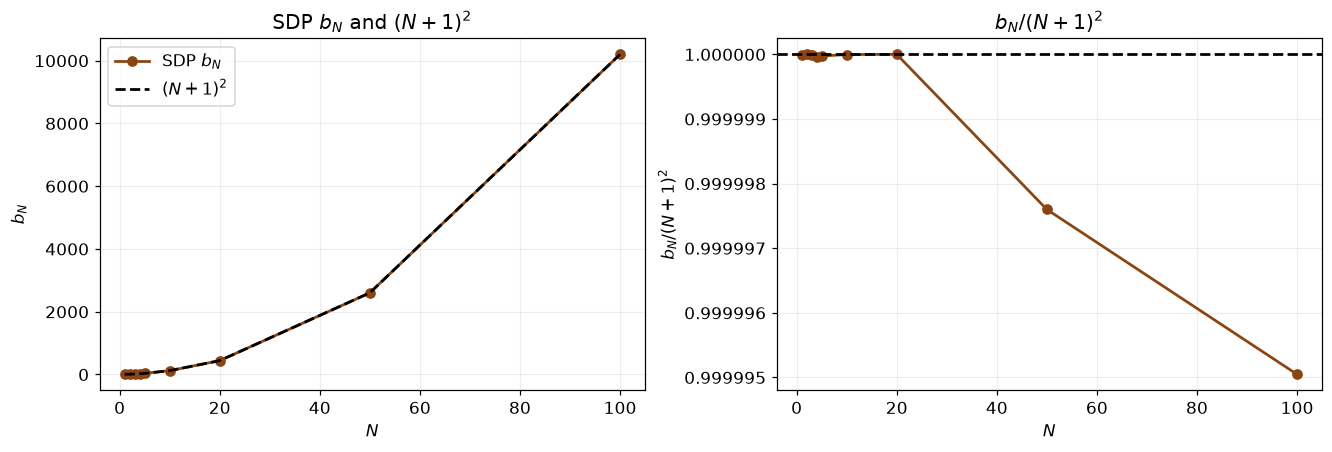

In [17]:
Ns = np.array(horizons)
bNs = np.array([results_by_N[N]["b_N"] for N in horizons])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].plot(Ns, bNs, "o-", color="saddlebrown", linewidth=1.8, label=r"SDP $b_N$")
axes[0].plot(Ns, (Ns + 1)**2, "--", color="black", linewidth=1.8, label=r"$(N+1)^2$")
axes[0].set(xlabel=r"$N$", ylabel=r"$b_N$", title=r"SDP $b_N$ and $(N+1)^2$")
axes[0].legend()
axes[1].plot(Ns, bNs / (Ns + 1)**2, "o-", color="saddlebrown", linewidth=1.8)
axes[1].axhline(1.0, color="black", linestyle="--", linewidth=1.8)
axes[1].set(xlabel=r"$N$", ylabel=r"$b_N/(N+1)^2$", title=r"$b_N/(N+1)^2$")
axes[1].ticklabel_format(axis="y", style="plain", useOffset=False)
plt.show()

#### 최종 계수의 패턴에서 중간 계수로

비교한 반복 횟수에서 $b_N^{\rm SDP}/(N+1)^2$는 1에 가깝다. 특히 $N=100$에서는 $b_N\approx10200.9495$로, 논문의 근삿값 $10201$을 재현한다.

$$b_N^{\rm opt}\approx(N+1)^2,\qquad
\|g_N\|^2\lesssim\frac{L^2\|x_0-x_\star\|^2}{(N+1)^2}.$$

여기까지는 비교한 유한한 $N$에서 얻은 수치적 관찰이다. 이제 모든 단계에서 potential 부등식을 만족하는 계수식을 찾기 위해, 큰 $b_N$을 얻은 $N=100$ 실험의 중간 계수들을 살펴본다.


### 큰 최종 계수를 만드는 중간 potential은 어떤 모습인가?

$N=100$, `relax=0`에서 구한 네 계수 수열을 그린다. Figure 1의 갈색 실선에 해당하는 해다.

$$\phi_k^f=a_k\|x_k-x_\star\|^2+b_k\|g_k\|^2
+2c_k\langle g_k,x_k-x_\star\rangle+d_k(f(x_k)-f_\star).$$

중간 상태의 계수는 자유롭게 두었지만, 마지막 상태의 $a_N=c_N=d_N=0$은 처음에 부여한 경계조건이다. 따라서 그래프의 끝점에서 이 계수들이 0인 것은 주어진 경계조건에 따른 결과다.


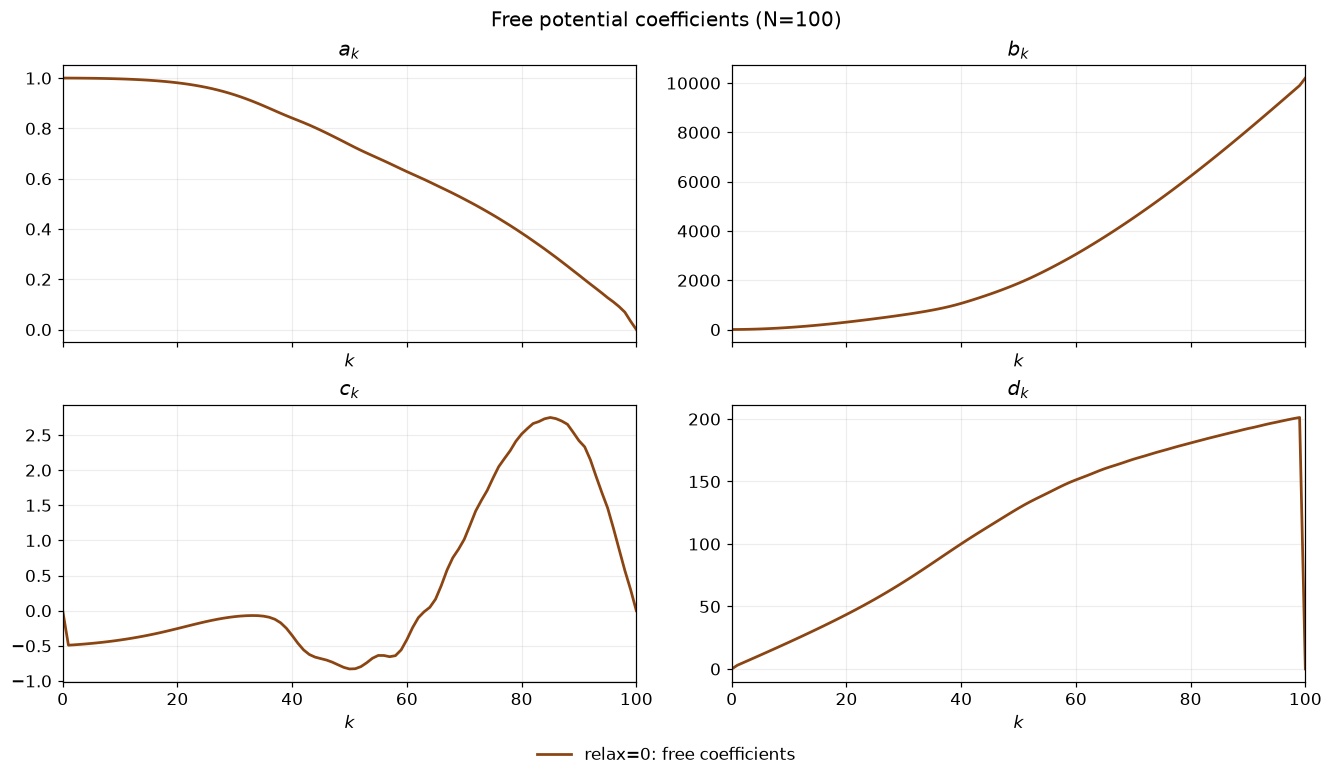

In [18]:
curves = [(free, "relax=0: free coefficients", "saddlebrown", "-")]
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, layout="constrained")
for key, ax in zip(("a", "b", "c", "d"), axes.flat):
    for result, label, color, linestyle in curves:
        ax.plot(np.arange(len(result[key])), result[key], label=label,
                color=color, linestyle=linestyle, linewidth=1.8)
    ax.set_title(rf"${key}_k$")
    ax.set_xlabel(r"$k$")
    ax.set_xlim(0, N_FIGURE)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
fig.suptitle(f"Free potential coefficients (N={N_FIGURE})")
plt.show()

초기·최종 상태와 일부 중간 상태의 계수를 수치로도 살펴본다. 아래 표는 상태 $k=0,1,25,50,75,100$에서 네 계수를 비교한다.


In [19]:
sample_k = sorted(set([0, 1, N_FIGURE // 4, N_FIGURE // 2, 3 * N_FIGURE // 4, N_FIGURE]))
headers = [r"$k$", r"$a_k$", r"$b_k$", r"$c_k$", r"$d_k$"]
rows = [(k, *(f"{free[key][k]:.6g}" for key in ("a", "b", "c", "d"))) for k in sample_k]
lines = ["| " + " | ".join(headers) + " |",
         "| " + " | ".join(["---"] * len(headers)) + " |"]
lines += ["| " + " | ".join(map(str, row)) + " |" for row in rows]
display(Markdown("\n".join(lines)))

| $k$ | $a_k$ | $b_k$ | $c_k$ | $d_k$ |
| --- | --- | --- | --- | --- |
| 0 | 1 | 0 | 0 | 0 |
| 1 | 0.999932 | 1.81581 | -0.491751 | 2.99715 |
| 25 | 0.962993 | 439.612 | -0.155759 | 55.9315 |
| 50 | 0.735249 | 1877.65 | -0.829792 | 128.626 |
| 75 | 0.455576 | 5345.37 | 1.88343 | 174.498 |
| 100 | 0 | 10200.9 | 0 | 0 |

#### 계수의 형태를 단순하게 제한해도 큰 $b_N$을 얻을 수 있는가?

기본 설정에서 구한 $a_k,c_k,d_k$는 단순한 상수나 직선 형태가 아니다. 예를 들어 $d_{50}\approx128.626$이며, 다음에 시험할 선형식의 값 $(2\cdot50+1)L=101$과 차이가 있다.

분석하기 쉬운 potential을 얻기 위해, 다음 실험에서는 논문의 설정에 따라 계수의 형태를 하나씩 제한한다. 먼저 함수값 계수를 $d_k=(2k+1)L$로 정하고, 이어 교차항을 없애며 거리항 계수를 고정한다. 계수에 이런 제약을 추가해도 큰 $b_N$을 유지할 수 있는지가 핵심 질문이다. 함수값 항을 아예 없앤 경우도 함께 비교하여 이 항의 역할을 살펴본다.


### Figure 1: 계수를 제한하며 potential 단순화하기

같은 $N=100$, $L=1$에서 아래 네 설정을 비교한다. 표의 중간 상태는 $k=1,\ldots,N-1$이다.

| `relax` | 중간 potential의 추가 조건 | 색 / 선 | $d_0$ | $a_N$ | $d_N$ |
| --- | --- | --- | --- | --- | --- |
| 0 | 없음 | 갈색 실선 | $0$ | $0$ | $0$ |
| 1 | $d_k=(2k+1)L$ | 빨간 점선 | $L$ | $0$ | $(2N+1)L$ |
| 2 | $d_k=(2k+1)L,\ c_k=0,\ a_k=L^2$ | 파란 점선 | $L$ | $L^2$ | $(2N+1)L$ |
| 3 | $d_k=0$ | 보라 점선 | $0$ | $0$ | $0$ |

모든 설정에서 $a_0=L^2$, $b_0=c_0=c_N=0$이다. 중간 계수뿐 아니라 초기·최종 potential도 참조 Python 코드의 설정에 맞게 정한다.

`relax=0,3`의 초기 potential은 $L^2\|x_0-x_\star\|^2$이고, `relax=1,2`에는 $L(f(x_0)-f_\star)$가 추가된다. 최종 potential도 표의 $a_N,d_N$에 따라 달라진다. 특히 `relax=2`가 보장하는 관계는

$$\begin{aligned}
L^2\|x_N-x_\star\|^2+b_N\|g_N\|^2+(2N+1)L(f(x_N)-f_\star)\\
\le L^2\|x_0-x_\star\|^2+L(f(x_0)-f_\star)
\end{aligned}$$

이다. 이후의 $b_N$ 비교에서는 이 경계조건의 차이도 함께 고려한다.


In [20]:
def linear_function_coefficient(k):
    dk = (2 * k + 1) * L
    Qk = cp.Variable((2, 2), symmetric=True, name=f"Q_{k+1}")
    return dk, Qk


def simple_potential_coefficient(k):
    dk = (2 * k + 1) * L
    Qk = cp.bmat([[L**2, 0], [0, cp.Variable(name=f"b_{k+1}")]])
    return dk, Qk


def no_function_coefficient(k):
    dk = 0
    Qk = cp.Variable((2, 2), symmetric=True, name=f"Q_{k+1}")
    return dk, Qk


figure_settings = {
    1: dict(d0=L, aN=0, dN=(2 * N_FIGURE + 1) * L,
            coefficient_rule=linear_function_coefficient),
    2: dict(d0=L, aN=L**2, dN=(2 * N_FIGURE + 1) * L,
            coefficient_rule=simple_potential_coefficient),
    3: dict(d0=0, aN=0, dN=0, coefficient_rule=no_function_coefficient),
}
figure_results = {0: free}
for relaxation, settings in figure_settings.items():
    figure_results[relaxation] = repeat_gd_sdp(N_FIGURE, **settings)
    figure_results[relaxation]["relax"] = relaxation

#### Figure 1의 네 계수 수열

갈색 실선은 중간 계수에 추가 제약을 두지 않은 `relax=0`의 수치해이고, 빨강·파랑·보라 점선은 각각 `relax=1,2,3`이다. 각 조건이 계수 수열의 모양과 최종 $b_N$에 어떤 변화를 주는지 비교한다.


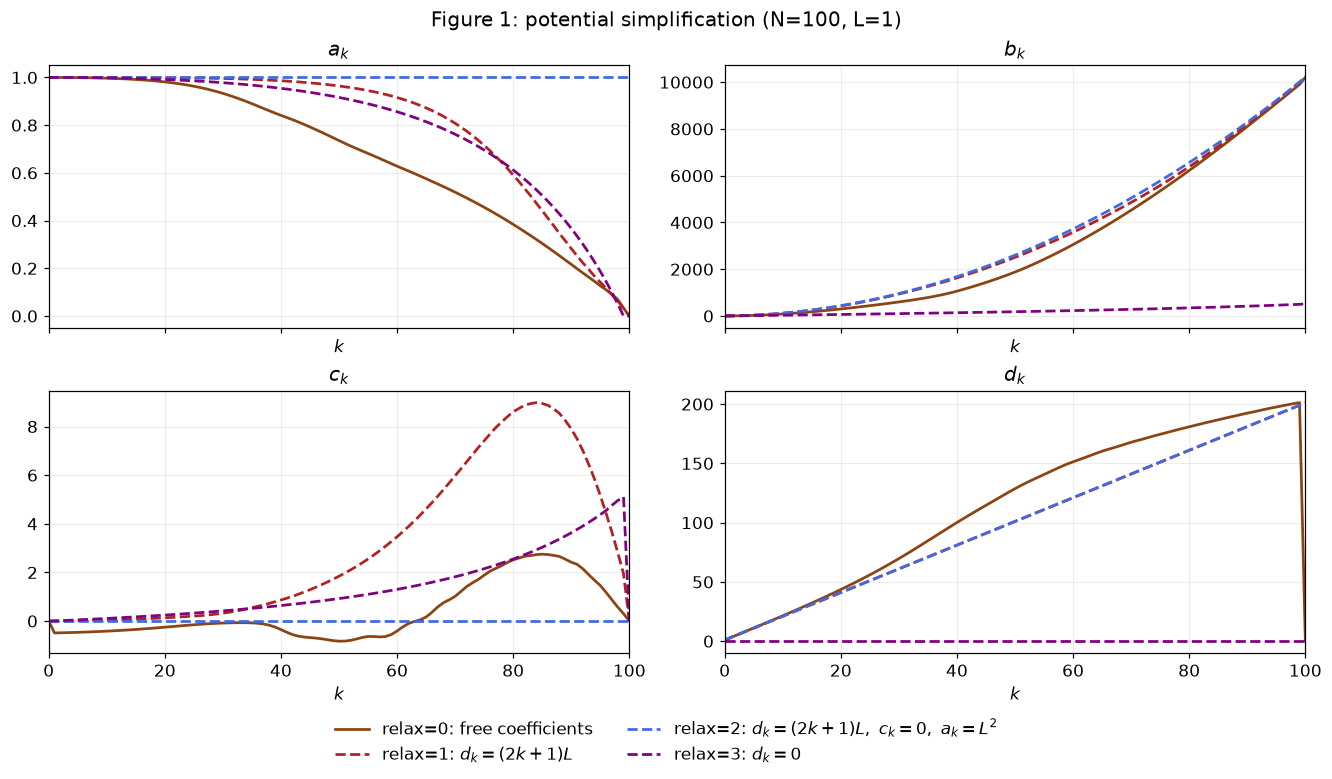

In [21]:
styles = {
    0: ("relax=0: free coefficients", "saddlebrown", "-"),
    1: (r"relax=1: $d_k=(2k+1)L$", "firebrick", "--"),
    2: (r"relax=2: $d_k=(2k+1)L,\ c_k=0,\ a_k=L^2$", "royalblue", "--"),
    3: (r"relax=3: $d_k=0$", "purple", "--"),
}
curves = [(figure_results[r], *styles[r]) for r in range(4)]
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, layout="constrained")
for key, ax in zip(("a", "b", "c", "d"), axes.flat):
    for result, label, color, linestyle in curves:
        ax.plot(np.arange(len(result[key])), result[key], label=label,
                color=color, linestyle=linestyle, linewidth=1.8)
    ax.set_title(rf"${key}_k$")
    ax.set_xlabel(r"$k$")
    ax.set_xlim(0, N_FIGURE)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
fig.suptitle(f"Figure 1: potential simplification (N={N_FIGURE}, L={L:g})")
plt.show()

각 설정의 최종 계수 $b_N$을 수치로 비교한다. 세 번째 열은 기본 실험에서 관찰한 $(N+1)^2$에 대한 비율이다.


In [22]:
headers = ["설정", r"$b_N$", r"$b_N/(N+1)^2$", "Solver 상태"]
rows = [(f"relax={relax}", f"{r['b_N']:.8f}",
         f"{r['b_N'] / (N_FIGURE + 1)**2:.6f}", r["status"])
        for relax, r in sorted(figure_results.items())]
lines = ["| " + " | ".join(headers) + " |",
         "| " + " | ".join(["---"] * len(headers)) + " |"]
lines += ["| " + " | ".join(map(str, row)) + " |" for row in rows]
display(Markdown("\n".join(lines)))

| 설정 | $b_N$ | $b_N/(N+1)^2$ | Solver 상태 |
| --- | --- | --- | --- |
| relax=0 | 10200.94948076 | 0.999995 | optimal |
| relax=1 | 10200.73009528 | 0.999974 | optimal |
| relax=2 | 10199.89142469 | 0.999891 | optimal |
| relax=3 | 517.10797950 | 0.050692 | optimal |

#### Figure 1에서 선택할 potential

$N=100$에서 기본 설정의 수치해는 $b_N\approx10200.9495$이고, 함수값 계수만 선형식으로 제한한 `relax=1`도 $10200.7301$을 얻는다. 교차항을 없애고 거리항 계수를 고정한 `relax=2`에서는 $10199.8914$로 여전히 약 $10200$이다. 함수값 항을 없앤 `relax=3`의 값은 $517.1080$이다.

설정마다 초기·최종 potential이 다르므로, 네 값을 비교할 때는 각 설정의 경계조건 차이도 고려해야 한다. 여기서 얻는 단서는 **함수값 항을 유지하면서 potential을 단순화해도 gradient norm 제곱 항에 큰 계수를 둘 수 있다**는 것이다. 논문은 $d_k=0$으로 제한한 potential로는 원하는 $O(N^{-2})$ gradient norm 제곱 수렴률을 증명할 수 없다고 보고한다.

이 결과를 바탕으로 다음 형태를 선택한다.

$$\boxed{\phi_k^f=L^2\|x_k-x_\star\|^2+b_k\|g_k\|^2+d_k(f(x_k)-f_\star).}$$

이것이 4단계에서 선택한 단순한 potential이다. 이제 남은 질문은 $b_k,d_k$를 어떻게 정해야 이 potential이 모든 단계에서 증가하지 않는가이다. 다음 단계에서 interpolation multiplier를 명시적으로 구성하여 이 질문에 답한다.


## 5단계 · 해석적 potential inequality와 수렴률

앞 단계의 수치 비교로 거리항 계수를 고정하고 교차항을 없앤 potential을 선택했다. 이제 함수값·gradient norm 제곱의 계수를 점화식으로 정하고, 그 potential이 모든 단계에서 증가하지 않음을 해석적으로 증명한다. 수치 탐색을 바탕으로 선택한 계수식이 모든 단계에서 potential 부등식을 만족함을 보이는 단계다.

### Theorem 3의 계수 점화식

Theorem 3은 $b_k,d_k\ge0$인 위의 potential에서

$$\boxed{d_{k+1}=d_k+2L,\qquad b_{k+1}=b_k+2+\frac{d_k}{L}}$$

이면 $\phi_{k+1}^f\le\phi_k^f$가 성립한다는 정리다.

먼저 interpolation 부등식의 가중합을 통해 두 점화식이 감소 조건을 만드는 이유를 확인한다. 그다음 초기조건에서 계수 수열을 구하고, Figure 1의 단순한 SDP 해와 비교한다.


### Appendix D.1: 세 부등식에 비음수 가중치 부여하기

GD 업데이트 $x_{k+1}=x_k-g_k/L$를 smooth convexity와 convexity 부등식에 대입하면 다음 세 식을 얻는다.

$$\begin{aligned}
I_1&=f(x_k)-f_\star-\langle g_k,x_k-x_\star\rangle
      +\frac1{2L}\|g_k\|^2\le0,\\
I_2&=f(x_{k+1})-f(x_k)+\frac1L\langle g_{k+1},g_k\rangle
      +\frac1{2L}\|g_{k+1}-g_k\|^2\le0,\\
I_3&=f(x_k)-f(x_{k+1})-\frac1L\|g_k\|^2\le0.
\end{aligned}$$

처음 두 식은 각각 $(\star,k)$, $(k,k+1)$에 대한 smooth interpolation 부등식에서 모든 항을 한쪽으로 옮겨 좌변이 0 이하가 되도록 쓴 것이다. 세 번째 식은 $f(x_{k+1})\ge f(x_k)+\langle g_k,x_{k+1}-x_k\rangle$에서 얻으며, gradient 차이에 대한 norm 제곱 항을 포함하지 않는다.

여기에 Appendix D.1의 가중치

$$\lambda_1=2L,\qquad
\lambda_2=2d_k+2L(2+b_k),\qquad
\lambda_3=d_k+2L(1+b_k)$$

를 곱한다. $b_k,d_k\ge0$이고 $L>0$이므로 세 가중치는 모두 비음수다. 따라서 가중합 $S_k=\lambda_1I_1+\lambda_2I_2+\lambda_3I_3$도 0 이하이다.


### 가중합을 potential 차이로 정리하기

먼저 $\langle g_{k+1},g_k\rangle/L+\|g_{k+1}-g_k\|^2/(2L)
=(\|g_{k+1}\|^2+\|g_k\|^2)/(2L)$를 이용해 내적항을 정리한다. 함수값과 gradient norm 제곱의 계수를 각각 모으면

$$\begin{aligned}
\lambda_1-\lambda_2+\lambda_3&=-d_k,&
\lambda_2-\lambda_3&=d_k+2L,\\
\frac{\lambda_1+\lambda_2}{2L}-\frac{\lambda_3}{L}&=1-b_k,&
\frac{\lambda_2}{2L}&=b_k+2+\frac{d_k}{L}
\end{aligned}$$

이다. 따라서 가중합의 함수값 항은 $(d_k+2L)(f(x_{k+1})-f_\star)-d_k(f(x_k)-f_\star)$가 된다. 첫 번째 점화식 $d_{k+1}=d_k+2L$은 이 항을 현재·다음 potential의 함수값 차이와 일치시킨다.

이차항까지 모두 쓰면

$$\begin{aligned}
S_k={}&(d_k+2L)(f(x_{k+1})-f_\star)-d_k(f(x_k)-f_\star)\\
&-2L\langle g_k,x_k-x_\star\rangle+(1-b_k)\|g_k\|^2
 +\left(b_k+2+\frac{d_k}{L}\right)\|g_{k+1}\|^2.
\end{aligned}$$

한편 GD 업데이트에 의해

$$L^2\|x_{k+1}-x_\star\|^2-L^2\|x_k-x_\star\|^2
=-2L\langle g_k,x_k-x_\star\rangle+\|g_k\|^2$$

이다. 이 거리항의 차이를 묶고 두 번째 점화식 $b_{k+1}=b_k+2+d_k/L$을 적용하면

$$S_k=\phi_{k+1}^f-\phi_k^f\le0$$

를 얻는다. 두 점화식은 interpolation 부등식의 가중합을 정확히 potential 차이로 만드는 조건이다.


### 같은 증명을 SDP의 LMI로 표현하기

앞에서 정의한 interpolation 부등식 $\mathcal I_{p,q}\ge0$와 방금 사용한 세 부등식의 관계는 다음과 같다.

$$I_1=-\mathcal I_{\star,k},\qquad
I_2=-\mathcal I_{k,k+1},\qquad
I_3=-\mathcal I_{k+1,k}-\frac1{2L}\|g_{k+1}-g_k\|^2.$$

따라서 $S_k=\Delta\phi_k$를 대입하면 정확한 항등식

$$\Delta\phi_k+
\lambda_1\mathcal I_{\star,k}+\lambda_2\mathcal I_{k,k+1}
+\lambda_3\mathcal I_{k+1,k}
=-\frac{\lambda_3}{2L}\|g_{k+1}-g_k\|^2\le0$$

을 얻는다. 함수값 계수는 모두 소거되고, 남는 제곱항을 Gram 표현으로 쓰면

$$r_k=0,\qquad
R_k=-\frac{\lambda_3}{2L}
(\mathbf g_{k+1}-\mathbf g_k)(\mathbf g_{k+1}-\mathbf g_k)^\top\preceq0.$$

같은 벡터와 그 전치의 곱은 PSD이고 $\lambda_3\ge0$이므로 오른쪽 행렬은 음의 준정부호다. 즉, 위 가중치를 사용하면 처음 구성한 SDP의 함수값 항이 소거되고 LMI가 성립함을 해석적으로 보일 수 있다. 이 증명은 모든 $b_k,d_k\ge0$와 $L>0$에 대해 성립한다.


### 초기조건에서 명시적 계수 수열 얻기

$d_0=L$, $b_0=0$으로 두고 점화식을 풀면

$$d_k=d_0+2Lk=(2k+1)L,\qquad
b_k=\sum_{t=0}^{k-1}\left(2+\frac{d_t}{L}\right)
=\sum_{t=0}^{k-1}(2t+3)=k(k+2)$$

이다. 따라서 네 계수는

$$\boxed{a_k=L^2,\qquad b_k=k(k+2),\qquad c_k=0,\qquad d_k=(2k+1)L.}$$

이 수열은 `relax=2`의 경계조건과 모든 한 단계 감소 부등식을 만족한다. 따라서 해당 설정의 정확한 SDP 최적값은 $b_N^{\rm opt}\ge N(N+2)$이다.

앞의 기본 설정에서 푼 SDP는 초기·최종 potential이 다르며, $(N+1)^2$는 그 실험에서 관찰한 수치 패턴이다. 이번 정리는 지금 구성한 명시적 계수 수열을 사용하면 potential이 매 단계 증가하지 않음을 보장한다. 아래에서는 이 수열을 `relax=2`의 수치해와 비교한다.


In [23]:
k = np.arange(N_FIGURE + 1)
analytical = {
    "a": np.full(N_FIGURE + 1, L**2),
    "b": (k * (k + 2)).astype(float),
    "c": np.zeros(N_FIGURE + 1),
    "d": (2 * k + 1) * L,
}
simplified = figure_results[2]

### 증명한 계수 수열과 수치해 비교하기

3·4단계에서 구한 수치 계수와 방금 증명한 계수식의 값을 비교한다. 파란 실선은 `relax=2`에서 구한 SDP 계수이고, 검정 점선은 Theorem 3의 명시적 수열이다. 두 수열을 같은 축에 그려 각 계수가 얼마나 가까운지 확인한다.


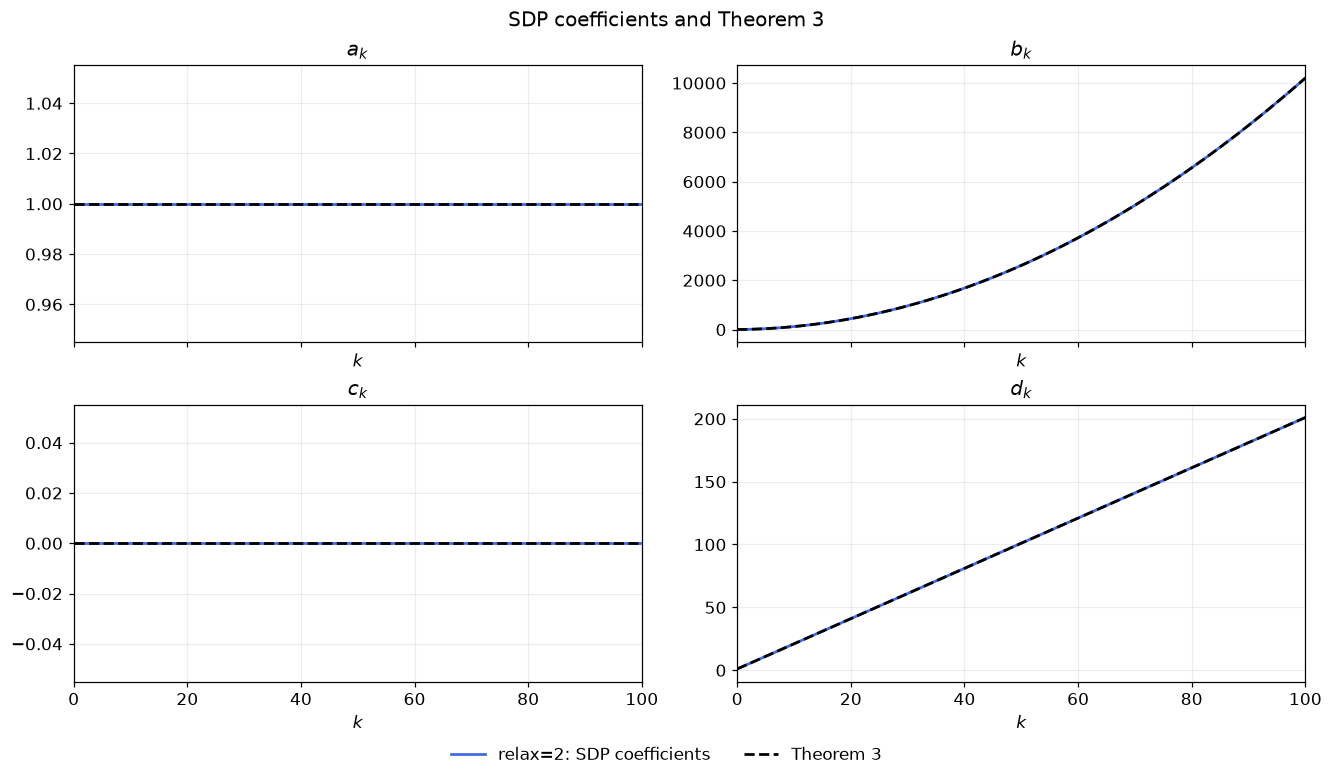

In [24]:
curves = [(simplified, "relax=2: SDP coefficients", "royalblue", "-"),
          (analytical, "Theorem 3", "black", "--")]
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, layout="constrained")
for key, ax in zip(("a", "b", "c", "d"), axes.flat):
    for result, label, color, linestyle in curves:
        ax.plot(np.arange(len(result[key])), result[key], label=label,
                color=color, linestyle=linestyle, linewidth=1.8)
    ax.set_title(rf"${key}_k$")
    ax.set_xlabel(r"$k$")
    ax.set_xlim(0, N_FIGURE)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
fig.suptitle("SDP coefficients and Theorem 3")
plt.show()

마지막 상태의 계수와 함께, 모든 상태에서 나타나는 최대 절대 차이를 비교한다.

$$\max_k|q_k^{\rm SDP}-q_k^{\rm theorem}|,\qquad q\in\{a,b,c,d\}.$$


In [25]:
headers = ["계수", r"SDP의 $k=N$ 값", r"Theorem 3의 $k=N$ 값", r"$\max_k \lvert q_k^{\rm SDP}-q_k^{\rm theorem}\rvert$"]
rows = [(rf"${key}_k$", f"{simplified[key][-1]:.8g}", f"{analytical[key][-1]:.8g}",
         f"{np.max(np.abs(simplified[key] - analytical[key])):.6g}")
        for key in ("a", "b", "c", "d")]
lines = ["| " + " | ".join(headers) + " |",
         "| " + " | ".join(["---"] * len(headers)) + " |"]
lines += ["| " + " | ".join(map(str, row)) + " |" for row in rows]
display(Markdown("\n".join(lines)))
print(f"SDP b_N - N(N+2) = {simplified['b_N'] - N_FIGURE * (N_FIGURE + 2):+.8g}")

| 계수 | SDP의 $k=N$ 값 | Theorem 3의 $k=N$ 값 | $\max_k \lvert q_k^{\rm SDP}-q_k^{\rm theorem}\rvert$ |
| --- | --- | --- | --- |
| $a_k$ | 1 | 1 | 0 |
| $b_k$ | 10199.891 | 10200 | 0.108575 |
| $c_k$ | 0 | 0 | 0 |
| $d_k$ | 201 | 201 | 0 |

SDP b_N - N(N+2) = -0.10857531


같은 형태의 potential에서 수치적으로 구한 계수와 해석적으로 구한 계수는 서로 매우 가깝다. 수치해의 $b_N\approx10199.8914$와 명시적 수열의 $N(N+2)=10200$ 사이의 차이는 약 $0.1086$이며, $10200$에 대한 상대 차이는 약 $1.06\times10^{-5}$이다.

MOSEK이 반환한 값은 유한 정밀도로 계산한 근삿값이다. 위에서 해석적으로 증명한 $b_N^{\rm opt}\ge10200$은 명시적 수열이 모든 제약을 만족한다는 사실에서 나온다. 수치해가 이 하한보다 조금 낮게 출력된 것은 근사 계산에 따른 수치 오차로 해석한다.

이제 명시적으로 구한 계수 수열을 potential 감소 부등식에 대입하여 함수값과 gradient norm 제곱의 수렴률을 얻는다.


### Telescoping으로 함수값과 gradient norm 제곱의 수렴률 얻기

$d_0=L$, $b_0=0$으로 시작한 Theorem 3의 수열은 다음 potential을 준다.

$$\phi_k^f=(2k+1)L(f(x_k)-f_\star)
+k(k+2)\|g_k\|^2+L^2\|x_k-x_\star\|^2.$$

앞에서 증명한 한 단계 감소 부등식을 반복하면

$$\phi_k^f\le\phi_0^f
=L(f(x_0)-f_\star)+L^2\|x_0-x_\star\|^2=:C_0.$$

왼쪽의 모든 항은 비음수다. 따라서 함수값 항 또는 gradient norm 제곱 항을 하나씩 남겨 각각의 상한을 얻는다.

$$\boxed{\begin{aligned}
f(x_k)-f_\star&\le\frac{C_0}{(2k+1)L}=O(k^{-1}),&&k\ge0,\\
\|g_k\|^2&\le\frac{C_0}{k(k+2)}=O(k^{-2}),&&k\ge1.
\end{aligned}}$$

또한 $L$-smoothness와 $g_\star=0$에서 $f(x_0)-f_\star\le\frac L2\|x_0-x_\star\|^2$이므로, gradient norm 제곱의 상한을 초기 거리만으로 쓰면

$$\|g_k\|^2\le
\frac{3L^2\|x_0-x_\star\|^2}{2k(k+2)},\qquad k\ge1.$$

Figure 1의 수치 탐색에서 선택한 단순한 potential로 함수값의 $O(k^{-1})$ 수렴률과 gradient norm 제곱의 $O(k^{-2})$ 수렴률을 함께 증명했다.

### 다음 사례: 조건부 기대값과 분산항이 들어오는 SGD

알고리즘과 가정에서 시작해 potential 설정, LMI/SDP 탐색, 계수 단순화, 해석적 증명까지 공통의 다섯 단계에 따라 GD를 분석했다. 이 사례에서는 정확한 gradient를 사용할 때 potential이 매 단계 증가하지 않음을 보였다.

다음 [Example II · Stochastic gradient descent](3_2_2_Figure_2_2A_StochasticGradientDescent.ipynb)에서도 같은 potential 형태와 Gram 표현, interpolation, LMI/SDP 탐색 절차를 사용한다. Stochastic oracle을 사용하므로 조건부 기대값과 분산 상한을 고려해야 하며, 한 단계 potential 부등식에는 분산에 따른 오차항이 추가된다. 다음에는 이 오차항이 반복에 따라 얼마나 누적되는지 살펴보고, averaging을 사용하면 그 누적을 줄일 수 있는지 분석한다.
